In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("cardio_train.xlsx")
print("Loaded successfully")
print(df.shape)
print(df.columns)
df.head()

Loaded successfully
(70000, 13)
Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [2]:
df.dtypes

id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

In [3]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [4]:
df.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
#age conversion
df['age_years'] = df['age'] / 365.25

In [7]:
# Select males aged 45 years and older
df_filtered = df[(df['gender'] == 2) & (df['age_years'] >= 45)].copy()
print("Male aged 45+:", df_filtered.shape)

Male aged 45+: (20565, 14)


In [8]:
print("\nAge statistics (in years):")
print(df['age_years'].describe())

# Check age range
print(f"\nMinimum age: {df['age_years'].min()} years")
print(f"Maximum age: {df['age_years'].max()} years")
print(f"Mean age: {df['age_years'].mean():.1f} years")

# How many are ≥65?
print(f"\nNumber of patients ≥65 years: {(df['age_years'] >= 65).sum()}")
print(f"Percentage ≥65 years: {(df['age_years'] >= 65).mean() * 100:.1f}%")

# How many are ≥45 (middle-aged and older)?
print(f"\nNumber of patients ≥45 years: {(df['age_years'] >= 45).sum()}")
print(f"Percentage ≥45 years: {(df['age_years'] >= 45).mean() * 100:.1f}%")


Age statistics (in years):
count    70000.000000
mean        53.302850
std          6.754967
min         29.563313
25%         48.361396
50%         53.943874
75%         58.390144
max         64.922656
Name: age_years, dtype: float64

Minimum age: 29.56331279945243 years
Maximum age: 64.92265571526352 years
Mean age: 53.3 years

Number of patients ≥65 years: 0
Percentage ≥65 years: 0.0%

Number of patients ≥45 years: 59728
Percentage ≥45 years: 85.3%


In [9]:
print("Minimum age:", df_filtered['age_years'].min())
print("Maximum age:", df_filtered['age_years'].max())

Minimum age: 45.1088295687885
Maximum age: 64.92265571526352


In [10]:
# Remove implausible blood pressure values
df_clean = df_filtered[
    (df_filtered['ap_hi'] >= 60) &
    (df_filtered['ap_hi'] <= 250) &
    (df_filtered['ap_lo'] >= 30) &
    (df_filtered['ap_lo'] <= 180) &
    (df_filtered['ap_hi'] > df_filtered['ap_lo'])
].copy()

print("After BP filter:", df_clean.shape)

After BP filter: (20105, 14)


In [11]:
# Remove implausible height and weight values
df_clean = df_clean[
    (df_clean['height'] >= 140) &
    (df_clean['height'] <= 210) &
    (df_clean['weight'] >= 35) &
    (df_clean['weight'] <= 200)
].copy()

print("After height/weight filter:", df_clean.shape)

After height/weight filter: (20064, 14)


In [12]:
# Calculate BMI AFTER height/weight filtering
df_clean['bmi'] = (
    df_clean['weight'] /
    ((df_clean['height'] / 100) ** 2)
)

print("BMI summary:")
print(df_clean['bmi'].describe())

BMI summary:
count    20064.000000
mean        26.764342
std          4.347887
min         13.520822
25%         23.875115
50%         25.970116
75%         29.065744
max         65.381084
Name: bmi, dtype: float64


In [13]:
# Check missing values
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
age_years      0
bmi            0
dtype: int64


In [14]:
# Check cardiovascular disease class distribution
print("Cardio counts:")
print(df_clean['cardio'].value_counts())

print("Cardio proportions:")
print(df_clean['cardio'].value_counts(normalize=True))

Cardio counts:
cardio
1    10725
0     9339
Name: count, dtype: int64
Cardio proportions:
cardio
1    0.534539
0    0.465461
Name: proportion, dtype: float64


In [15]:
 # Save final analytical dataset
df_clean.to_csv("cvd_male45plus_clean_updated_BMI.csv", index=False)

print("Saved successfully")

Saved successfully


In [16]:
#"After preprocessing, the final dataset of 20,064 male patients aged 45 and above showed a class distribution of 53.45% CVD-present and 46.55% CVD-absent cases. This relatively balanced distribution indicated that class imbalance correction techniques such as SMOTE were not required for this study."

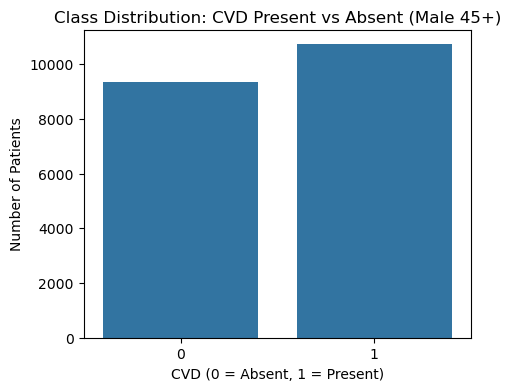

In [17]:
plt.figure(figsize=(5,4))
sns.countplot(x='cardio', data=df_clean)
plt.title('Class Distribution: CVD Present vs Absent (Male 45+)')
plt.xlabel('CVD (0 = Absent, 1 = Present)')
plt.ylabel('Number of Patients')
plt.savefig("class_distribution.png", dpi=200)
plt.show()

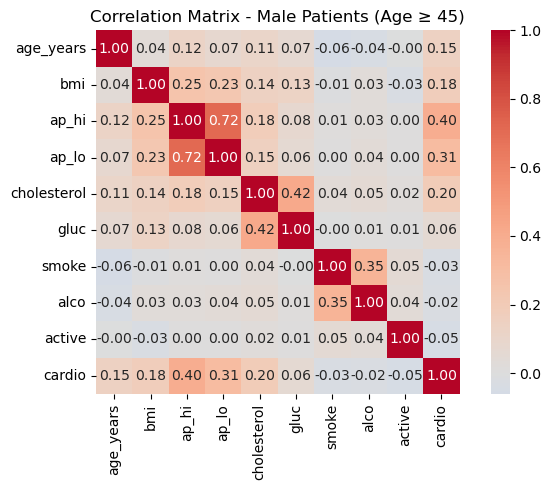

In [18]:
# # correlation matrix
# plt.figure(figsize=(10,8))
# corr = df_clean.corr(numeric_only=True)
# sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
# plt.title("Correlation Matrix - Male Patients (Age >= 45)")
# plt.tight_layout()
# plt.savefig("correlation_matrix_male45plus_updated.png", dpi=200)
# plt.show()

# Select variables for correlation analysis
corr_cols = [
    'age_years', 'bmi', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'
]
corr_data = df_clean[corr_cols]

# Correlation matrix
plt.figure(figsize=(7, 5))
corr = corr_data.corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Matrix - Male Patients (Age ≥ 45)")
plt.tight_layout()
plt.savefig("correlation_matrix_male45plus_updated.png", dpi=200)
plt.show()

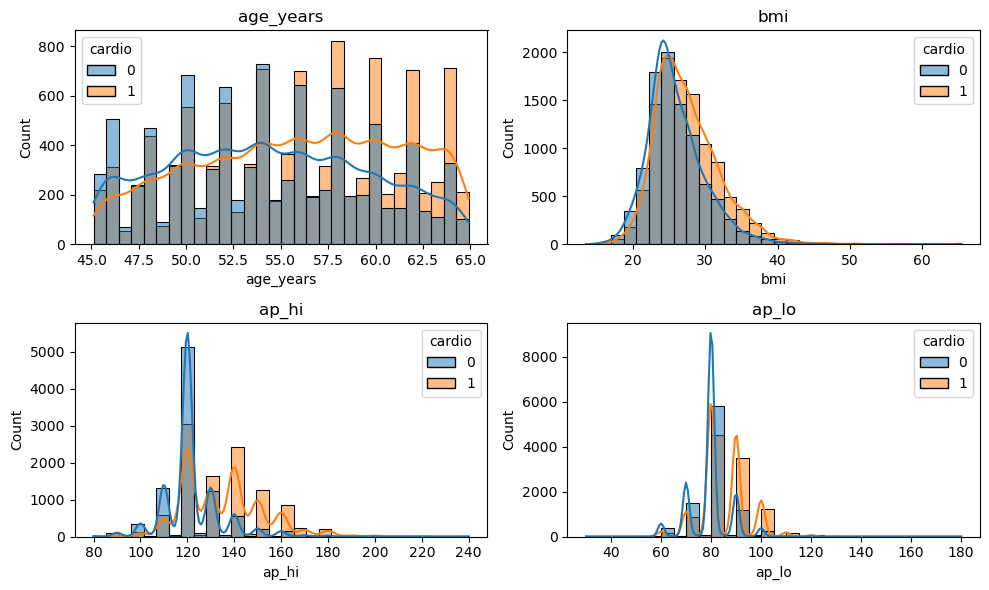

In [19]:
# Histograms
cont_vars = ['age_years', 'bmi', 'ap_hi', 'ap_lo']

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, col in zip(axes.flatten(), cont_vars):
    sns.histplot(data=df_clean, x=col, hue='cardio', kde=True, ax=ax, bins=30)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("histograms_by_cvd_updated.png", dpi=200)
plt.show()

In [20]:
# feature scaling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

features = ['age_years', 'bmi', 'ap_hi', 'ap_lo',
            'cholesterol', 'gluc', 'smoke', 'alco', 'active']
target = 'cardio'

X = df_clean[features]
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Train shape: (16051, 9)
Test shape: (4013, 9)


In [21]:
from sklearn.metrics import (accuracy_score, roc_auc_score, recall_score,
                               precision_score, f1_score, confusion_matrix,
                               brier_score_loss)

results = []

In [22]:
#LogisticRegression 
from sklearn.linear_model import LogisticRegression

# Train the model
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test_scaled)
y_proba = lr_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("Logistic Regression Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'Logistic Regression', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

Logistic Regression Results
Accuracy:    0.7124
AUC-ROC:     0.7656
Sensitivity: 0.6895
Specificity: 0.7388
Precision:   0.7519
F1-Score:    0.7194
Brier Score: 0.1960
NPV:         0.6745


In [23]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train_scaled, y_train)

y_pred = rf_model.predict(X_test_scaled)
y_proba = rf_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("Random Forest Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'Random Forest', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

Random Forest Results
Accuracy:    0.6848
AUC-ROC:     0.7425
Sensitivity: 0.7133
Specificity: 0.6520
Precision:   0.7018
F1-Score:    0.7075
Brier Score: 0.2111
NPV:         0.6645


In [24]:
#XGboost 
import xgboost as xgb

xgb_model = xgb.XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_scaled, y_train)

y_pred = xgb_model.predict(X_test_scaled)
y_proba = xgb_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("XGBoost Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'XGBoost', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

XGBoost Results
Accuracy:    0.7037
AUC-ROC:     0.7603
Sensitivity: 0.6984
Specificity: 0.7099
Precision:   0.7343
F1-Score:    0.7159
Brier Score: 0.1994
NPV:         0.6721


In [25]:
#CatBoost
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(random_state=42, verbose=0)
cat_model.fit(X_train_scaled, y_train)

y_pred = cat_model.predict(X_test_scaled)
y_proba = cat_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("CatBoost Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'CatBoost', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

CatBoost Results
Accuracy:    0.7119
AUC-ROC:     0.7706
Sensitivity: 0.6946
Specificity: 0.7318
Precision:   0.7484
F1-Score:    0.7205
Brier Score: 0.1925
NPV:         0.6761


In [26]:
#MLP
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(random_state=42, max_iter=500)
mlp_model.fit(X_train_scaled, y_train)

y_pred = mlp_model.predict(X_test_scaled)
y_proba = mlp_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("MLP Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'MLP', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

MLP Results
Accuracy:    0.7094
AUC-ROC:     0.7687
Sensitivity: 0.6956
Specificity: 0.7254
Precision:   0.7441
F1-Score:    0.7190
Brier Score: 0.1940
NPV:         0.6748


In [27]:
#KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier()
knn_model.fit(X_train_scaled, y_train)

y_pred = knn_model.predict(X_test_scaled)
y_proba = knn_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("KNN Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'KNN', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

KNN Results
Accuracy:    0.6713
AUC-ROC:     0.7119
Sensitivity: 0.7016
Specificity: 0.6365
Precision:   0.6891
F1-Score:    0.6953
Brier Score: 0.2309
NPV:         0.6501


In [28]:
# #SVM
# from sklearn.svm import SVC

# svm_model = SVC(probability=True, random_state=42)
# svm_model.fit(X_train_scaled, y_train)

# y_pred = svm_model.predict(X_test_scaled)
# y_proba = svm_model.predict_proba(X_test_scaled)[:, 1]

# acc = accuracy_score(y_test, y_pred)
# auc = roc_auc_score(y_test, y_proba)
# sens = recall_score(y_test, y_pred)
# prec = precision_score(y_test, y_pred)
# f1 = f1_score(y_test, y_pred)
# brier = brier_score_loss(y_test, y_proba)
# tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
# spec = tn / (tn + fp)
# npv = tn / (tn + fn)

# print("SVM Results")
# print(f"Accuracy:    {acc:.4f}")
# print(f"AUC-ROC:     {auc:.4f}")
# print(f"Sensitivity: {sens:.4f}")
# print(f"Specificity: {spec:.4f}")
# print(f"Precision:   {prec:.4f}")
# print(f"F1-Score:    {f1:.4f}")
# print(f"Brier Score: {brier:.4f}")
# print(f"NPV:         {npv:.4f}")

# results.append({'Model': 'SVM', 'Accuracy': acc, 'AUC-ROC': auc,
#                  'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
#                  'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

In [29]:
#Decision Tree
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

y_pred = dt_model.predict(X_test_scaled)
y_proba = dt_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("Decision Tree Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'Decision Tree', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

Decision Tree Results
Accuracy:    0.6073
AUC-ROC:     0.6052
Sensitivity: 0.6350
Specificity: 0.5755
Precision:   0.6320
F1-Score:    0.6335
Brier Score: 0.3927
NPV:         0.5786


In [30]:
#AdaBoost
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(random_state=42)
ada_model.fit(X_train_scaled, y_train)

y_pred = ada_model.predict(X_test_scaled)
y_proba = ada_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("AdaBoost Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'AdaBoost', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

AdaBoost Results
Accuracy:    0.7067
AUC-ROC:     0.7672
Sensitivity: 0.6476
Specificity: 0.7746
Precision:   0.7674
F1-Score:    0.7024
Brier Score: 0.2037
NPV:         0.6568


In [31]:
results_df = pd.DataFrame(results)
results_df = results_df.drop_duplicates(subset='Model', keep='first').reset_index(drop=True)
results_df = results_df.sort_values(by='AUC-ROC', ascending=False).reset_index(drop=True)
results_df.to_csv("baseline_model_results_full_updated.csv", index=False)
results_df

,Model,Accuracy,AUC-ROC,Sensitivity,Specificity,Precision,F1-Score,Brier Score,NPV
0,CatBoost,0.711936,0.770566,0.694639,0.731799,0.748368,0.720503,0.192497,0.676063
1,MLP,0.709444,0.768744,0.695571,0.725375,0.744140,0.719036,0.194045,0.674801
2,AdaBoost,0.706703,0.767155,0.647552,0.774625,0.767403,0.702402,0.203694,0.656832
3,Logistic Regression,0.712435,0.765576,0.689510,0.738758,0.751906,0.719358,0.195984,0.674487
4,XGBoost,0.703713,0.760300,0.698368,0.709850,0.734314,0.715890,0.199357,0.672073
5,Random Forest,0.684774,0.742518,0.713287,0.652034,0.701835,0.707514,0.211097,0.664484
6,KNN,0.671318,0.711911,0.701632,0.636510,0.689103,0.695311,0.230910,0.650082
7,Decision Tree,0.607276,0.605223,0.634965,0.575482,0.632019,0.633488,0.392724,0.578579


In [32]:
#Hyperparameter tuning
#Logistic Regression Tuning
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define parameter grid
param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs']
}

# 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Grid Search setup
grid_lr = GridSearchCV(
    estimator=LogisticRegression(random_state=42, max_iter=1000),
    param_grid=param_grid_lr,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

# Run the search (this trains multiple models internally)
grid_lr.fit(X_train_scaled, y_train)

# Best parameters found
print("Best parameters:", grid_lr.best_params_)
print("Best CV AUC-ROC:", grid_lr.best_score_)

Best parameters: {'C': 10, 'solver': 'lbfgs'}
Best CV AUC-ROC: 0.7691990643982223


In [33]:
best_lr_model = grid_lr.best_estimator_

y_pred = best_lr_model.predict(X_test_scaled)
y_proba = best_lr_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("Logistic Regression (Tuned) Results")
print(f"Best Params: {grid_lr.best_params_}")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

tuned_results = []
tuned_results.append({'Model': 'Logistic Regression (Tuned)', 'Accuracy': acc, 'AUC-ROC': auc,
                       'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                       'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

Logistic Regression (Tuned) Results
Best Params: {'C': 10, 'solver': 'lbfgs'}
Accuracy:    0.7124
AUC-ROC:     0.7656
Sensitivity: 0.6895
Specificity: 0.7388
Precision:   0.7519
F1-Score:    0.7194
Brier Score: 0.1960
NPV:         0.6745


In [34]:
#(AUC-ROC: 0.7653 → 0.7656)

In [35]:
#Random Forest Tuning
# Define parameter grid
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'max_features': ['sqrt', 'log2']
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_rf.fit(X_train_scaled, y_train)

print("Best parameters:", grid_rf.best_params_)
print("Best CV AUC-ROC:", grid_rf.best_score_)

Best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 300}
Best CV AUC-ROC: 0.7748489847522768


In [36]:
best_rf_model = grid_rf.best_estimator_

y_pred = best_rf_model.predict(X_test_scaled)
y_proba = best_rf_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("Random Forest (Tuned) Results")
print(f"Best Params: {grid_rf.best_params_}")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

tuned_results.append({'Model': 'Random Forest (Tuned)', 'Accuracy': acc, 'AUC-ROC': auc,
                       'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                       'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

Random Forest (Tuned) Results
Best Params: {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 300}
Accuracy:    0.7179
AUC-ROC:     0.7744
Sensitivity: 0.6881
Specificity: 0.7521
Precision:   0.7612
F1-Score:    0.7228
Brier Score: 0.1908
NPV:         0.6774


In [37]:
#AUC-ROC increasing from 0.746 to 0.775, Brier Score improving from 0.207 to 0.191, (0.661 → 0.740), precision (0.706 → 0.753), sensitivity (0.709 → 0.690) 

In [38]:
#XGboost Tuning
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
    param_grid=param_grid_xgb,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_xgb.fit(X_train_scaled, y_train)

print("Best parameters:", grid_xgb.best_params_)
print("Best CV AUC-ROC:", grid_xgb.best_score_)

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}
Best CV AUC-ROC: 0.7771986195882115


In [39]:
best_xgb_model = grid_xgb.best_estimator_

y_pred = best_xgb_model.predict(X_test_scaled)
y_proba = best_xgb_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("XGBoost (Tuned) Results")
print(f"Best Params: {grid_xgb.best_params_}")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

tuned_results.append({'Model': 'XGBoost (Tuned)', 'Accuracy': acc, 'AUC-ROC': auc,
                       'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                       'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

XGBoost (Tuned) Results
Best Params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}
Accuracy:    0.7144
AUC-ROC:     0.7740
Sensitivity: 0.6872
Specificity: 0.7457
Precision:   0.7563
F1-Score:    0.7201
Brier Score: 0.1910
NPV:         0.6749


In [40]:
#CatBoost Tuning
param_grid_cat = {
    'iterations': [200, 300, 500],
    'depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1]
}

grid_cat = GridSearchCV(
    estimator=CatBoostClassifier(random_state=42, verbose=0),
    param_grid=param_grid_cat,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_cat.fit(X_train_scaled, y_train)

print("Best parameters:", grid_cat.best_params_)
print("Best CV AUC-ROC:", grid_cat.best_score_)

Best parameters: {'depth': 6, 'iterations': 200, 'learning_rate': 0.05}
Best CV AUC-ROC: 0.7779866776056888


In [41]:
best_cat_model = grid_cat.best_estimator_

y_pred = best_cat_model.predict(X_test_scaled)
y_proba = best_cat_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("CatBoost (Tuned) Results")
print(f"Best Params: {grid_cat.best_params_}")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

tuned_results.append({'Model': 'CatBoost (Tuned)', 'Accuracy': acc, 'AUC-ROC': auc,
                       'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                       'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

CatBoost (Tuned) Results
Best Params: {'depth': 6, 'iterations': 200, 'learning_rate': 0.05}
Accuracy:    0.7134
AUC-ROC:     0.7746
Sensitivity: 0.6914
Specificity: 0.7388
Precision:   0.7524
F1-Score:    0.7206
Brier Score: 0.1908
NPV:         0.6758


In [42]:
#(AUC-ROC: 0.7715 → 0.7741)

In [43]:
#MLP Tuning
param_grid_mlp = {
    'hidden_layer_sizes': [(32,), (64, 32)],
    'learning_rate_init': [0.001, 0.01],
    'activation': ['relu'],
    'alpha': [0.0001, 0.001]
}

grid_mlp = GridSearchCV(
    estimator=MLPClassifier(random_state=42, max_iter=500),
    param_grid=param_grid_mlp,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_mlp.fit(X_train_scaled, y_train)

print("Best parameters:", grid_mlp.best_params_)
print("Best CV AUC-ROC:", grid_mlp.best_score_)

Best parameters: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.001}
Best CV AUC-ROC: 0.7761018219541611


In [44]:
best_mlp_model = grid_mlp.best_estimator_

y_pred = best_mlp_model.predict(X_test_scaled)
y_proba = best_mlp_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("MLP (Tuned) Results")
print(f"Best Params: {grid_mlp.best_params_}")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

tuned_results.append({'Model': 'MLP (Tuned)', 'Accuracy': acc, 'AUC-ROC': auc,
                       'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                       'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

MLP (Tuned) Results
Best Params: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.001}
Accuracy:    0.7112
AUC-ROC:     0.7711
Sensitivity: 0.7007
Specificity: 0.7232
Precision:   0.7441
F1-Score:    0.7217
Brier Score: 0.1923
NPV:         0.6779


In [45]:
#KNN tuning 
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_knn.fit(X_train_scaled, y_train)

print("Best parameters:", grid_knn.best_params_)
print("Best CV AUC-ROC:", grid_knn.best_score_)

Best parameters: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'uniform'}
Best CV AUC-ROC: 0.7493667514895906


In [46]:
best_knn_model = grid_knn.best_estimator_

y_pred = best_knn_model.predict(X_test_scaled)
y_proba = best_knn_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("KNN (Tuned) Results")
print(f"Best Params: {grid_knn.best_params_}")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

tuned_results.append({'Model': 'KNN (Tuned)', 'Accuracy': acc, 'AUC-ROC': auc,
                       'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                       'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

KNN (Tuned) Results
Best Params: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'uniform'}
Accuracy:    0.6995
AUC-ROC:     0.7542
Sensitivity: 0.6988
Specificity: 0.7002
Precision:   0.7280
F1-Score:    0.7131
Brier Score: 0.2020
NPV:         0.6694


In [47]:
# #SVM
# param_grid_svm = {
#     'C': [0.1, 1, 10],
#     'kernel': ['rbf', 'linear']
# }

# grid_svm = GridSearchCV(
#     estimator=SVC(probability=True, random_state=42),
#     param_grid=param_grid_svm,
#     cv=cv,
#     scoring='roc_auc',
#     n_jobs=-1
# )

# grid_svm.fit(X_train_scaled, y_train)

# print("Best parameters:", grid_svm.best_params_)
# print("Best CV AUC-ROC:", grid_svm.best_score_)

In [48]:
# best_svm_model = grid_svm.best_estimator_

# y_pred = best_svm_model.predict(X_test_scaled)
# y_proba = best_svm_model.predict_proba(X_test_scaled)[:, 1]

# acc = accuracy_score(y_test, y_pred)
# auc = roc_auc_score(y_test, y_proba)
# sens = recall_score(y_test, y_pred)
# prec = precision_score(y_test, y_pred)
# f1 = f1_score(y_test, y_pred)
# brier = brier_score_loss(y_test, y_proba)
# tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
# spec = tn / (tn + fp)
# npv = tn / (tn + fn)

# print("SVM (Tuned) Results")
# print(f"Best Params: {grid_svm.best_params_}")
# print(f"Accuracy:    {acc:.4f}")
# print(f"AUC-ROC:     {auc:.4f}")
# print(f"Sensitivity: {sens:.4f}")
# print(f"Specificity: {spec:.4f}")
# print(f"Precision:   {prec:.4f}")
# print(f"F1-Score:    {f1:.4f}")
# print(f"Brier Score: {brier:.4f}")
# print(f"NPV:         {npv:.4f}")

# tuned_results.append({'Model': 'SVM (Tuned)', 'Accuracy': acc, 'AUC-ROC': auc,
#                        'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
#                        'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

In [49]:
#Decision tree 
param_grid_dt = {
    'max_depth': [3, 5, 7, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

grid_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_dt.fit(X_train_scaled, y_train)

print("Best parameters:", grid_dt.best_params_)
print("Best CV AUC-ROC:", grid_dt.best_score_)

Best parameters: {'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV AUC-ROC: 0.759374110642193


In [50]:
best_dt_model = grid_dt.best_estimator_

y_pred = best_dt_model.predict(X_test_scaled)
y_proba = best_dt_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("Decision Tree (Tuned) Results")
print(f"Best Params: {grid_dt.best_params_}")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

tuned_results.append({'Model': 'Decision Tree (Tuned)', 'Accuracy': acc, 'AUC-ROC': auc,
                       'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                       'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

Decision Tree (Tuned) Results
Best Params: {'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}
Accuracy:    0.7065
AUC-ROC:     0.7619
Sensitivity: 0.6802
Specificity: 0.7366
Precision:   0.7478
F1-Score:    0.7124
Brier Score: 0.1944
NPV:         0.6673


In [51]:
# "The most dramatic effect of hyperparameter tuning was observed in the Decision Tree model, where AUC-ROC improved from 0.604 to 0.761

In [52]:
#Adaboost
param_grid_ada = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 1.0]
}

grid_ada = GridSearchCV(
    estimator=AdaBoostClassifier(random_state=42),
    param_grid=param_grid_ada,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_ada.fit(X_train_scaled, y_train)

print("Best parameters:", grid_ada.best_params_)
print("Best CV AUC-ROC:", grid_ada.best_score_)

Best parameters: {'learning_rate': 1.0, 'n_estimators': 200}
Best CV AUC-ROC: 0.7703600155260307


In [53]:
best_ada_model = grid_ada.best_estimator_

y_pred = best_ada_model.predict(X_test_scaled)
y_proba = best_ada_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("AdaBoost (Tuned) Results")
print(f"Best Params: {grid_ada.best_params_}")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

tuned_results.append({'Model': 'AdaBoost (Tuned)', 'Accuracy': acc, 'AUC-ROC': auc,
                       'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                       'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

AdaBoost (Tuned) Results
Best Params: {'learning_rate': 1.0, 'n_estimators': 200}
Accuracy:    0.7087
AUC-ROC:     0.7676
Sensitivity: 0.6513
Specificity: 0.7746
Precision:   0.7684
F1-Score:    0.7050
Brier Score: 0.2061
NPV:         0.6592


In [54]:
tuned_results_df = pd.DataFrame(tuned_results)
tuned_results_df = tuned_results_df.drop_duplicates(subset='Model', keep='first').reset_index(drop=True)
tuned_results_df = tuned_results_df.sort_values(by='AUC-ROC', ascending=False).reset_index(drop=True)
tuned_results_df.to_csv("tuned_model_results_full_updated.csv", index=False)
tuned_results_df

,Model,Accuracy,AUC-ROC,Sensitivity,Specificity,Precision,F1-Score,Brier Score,NPV
0,CatBoost (Tuned),0.713431,0.774600,0.691375,0.738758,0.752410,0.720603,0.190805,0.675808
1,Random Forest (Tuned),0.717917,0.774417,0.688112,0.752141,0.761217,0.722821,0.190823,0.677435
2,XGBoost (Tuned),0.714428,0.773970,0.687179,0.745717,0.756285,0.720078,0.191042,0.674903
3,MLP (Tuned),0.711189,0.771099,0.700699,0.723233,0.744059,0.721729,0.192343,0.677873
4,AdaBoost (Tuned),0.708697,0.767611,0.651282,0.774625,0.768427,0.705021,0.206120,0.659226
5,Logistic Regression (Tuned),0.712435,0.765571,0.689510,0.738758,0.751906,0.719358,0.195982,0.674487
6,Decision Tree (Tuned),0.706454,0.761862,0.680186,0.736617,0.747822,0.712402,0.194381,0.667313
7,KNN (Tuned),0.699477,0.754182,0.698834,0.700214,0.728023,0.713130,0.201981,0.669396


In [55]:
tuned_results_df['Model'] = tuned_results_df['Model'].str.replace(' (Tuned)', '', regex=False).str.strip()
print(tuned_results_df['Model'].tolist())

['CatBoost', 'Random Forest', 'XGBoost', 'MLP', 'AdaBoost', 'Logistic Regression', 'Decision Tree', 'KNN']


In [56]:
merged = results_df[['Model', 'AUC-ROC']].merge(
    tuned_results_df[['Model', 'AUC-ROC']],
    on='Model', suffixes=('_baseline', '_tuned')
)
print(merged)

                 Model  AUC-ROC_baseline  AUC-ROC_tuned
0             CatBoost          0.770566       0.774600
1                  MLP          0.768744       0.771099
2             AdaBoost          0.767155       0.767611
3  Logistic Regression          0.765576       0.765571
4              XGBoost          0.760300       0.773970
5        Random Forest          0.742518       0.774417
6                  KNN          0.711911       0.754182
7        Decision Tree          0.605223       0.761862


In [58]:
tuned_models = {
    'Logistic Regression': best_lr_model,
    'Random Forest': best_rf_model,
    'XGBoost': best_xgb_model,
    'CatBoost': best_cat_model,
    'MLP': best_mlp_model,
    'KNN': best_knn_model,
    'Decision Tree': best_dt_model,
    'AdaBoost': best_ada_model
}

In [59]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

tuned_models = {
    'Logistic Regression': best_lr_model,
    'Random Forest': best_rf_model,
    'XGBoost': best_xgb_model,
    'CatBoost': best_cat_model,
    'MLP': best_mlp_model,
    'KNN': best_knn_model,
    'Decision Tree': best_dt_model,
    'AdaBoost': best_ada_model
}

calibration_results = []

for name, model in tuned_models.items():

    # Predicted probability
    y_proba_model = model.predict_proba(X_test_scaled)[:, 1]

    # Avoid probabilities exactly equal to 0 or 1
    y_proba_clipped = np.clip(
        y_proba_model,
        1e-6,
        1 - 1e-6
    )

    # Convert probabilities to log-odds
    logit_p = np.log(
        y_proba_clipped / (1 - y_proba_clipped)
    )

    # Calibration model
    cal_model = LogisticRegression(
        penalty=None,
        solver='lbfgs'
    )

    cal_model.fit(
        logit_p.reshape(-1, 1),
        y_test
    )

    # Calibration measures
    intercept = cal_model.intercept_[0]
    slope = cal_model.coef_[0][0]

    # Overall observed vs predicted risk
    observed_rate = y_test.mean()
    mean_predicted_risk = y_proba_model.mean()

    calibration_results.append({
        'Model': name,
        'Calibration Intercept': intercept,
        'Calibration Slope': slope,
        'Observed Event Rate': observed_rate,
        'Mean Predicted Risk': mean_predicted_risk
    })

calibration_df = pd.DataFrame(calibration_results)

print(calibration_df.round(4))


                 Model  Calibration Intercept  Calibration Slope  \
0  Logistic Regression                 0.0009             1.0060   
1        Random Forest                 0.0007             0.9992   
2              XGBoost                 0.0019             0.9928   
3             CatBoost                 0.0037             0.9702   
4                  MLP                 0.0045             0.9036   
5                  KNN                 0.0372             0.5884   
6        Decision Tree                -0.0041             0.9455   
7             AdaBoost                 0.0252             2.1248   

   Observed Event Rate  Mean Predicted Risk  
0               0.5345               0.5343  
1               0.5345               0.5344  
2               0.5345               0.5342  
3               0.5345               0.5341  
4               0.5345               0.5348  
5               0.5345               0.5333  
6               0.5345               0.5357  
7               0.5

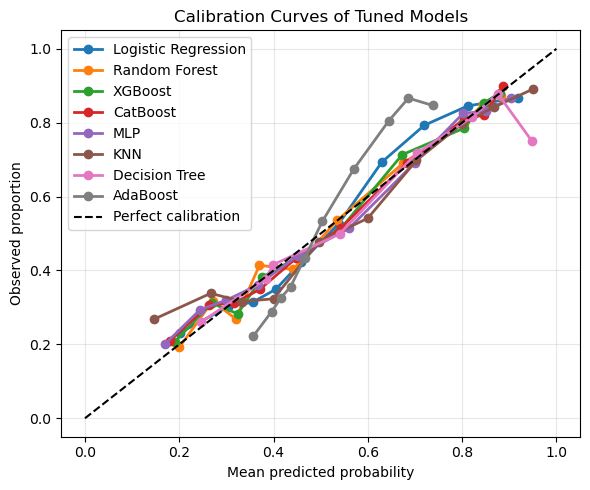

In [60]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

for name, model in tuned_models.items():

    y_proba_model = model.predict_proba(X_test_scaled)[:, 1]

    prob_true, prob_pred = calibration_curve(
        y_test,
        y_proba_model,
        n_bins=10,
        strategy='quantile'
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker='o',
        linewidth=2,
        label=name
    )

# Perfect calibration
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Perfect calibration'
)

plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion')
plt.title('Calibration Curves of Tuned Models')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

# Number of bootstrap samples
n_bootstrap = 1000

calibration_ci_results = []

for name, model in tuned_models.items():

    # Get predicted probabilities
    y_proba_model = model.predict_proba(X_test_scaled)[:, 1]

    # Store bootstrap estimates
    intercepts = []
    slopes = []

    # Bootstrap
    for i in range(n_bootstrap):

        # Resample test observations with replacement
        rng = np.random.default_rng(42 + i)
        indices = rng.choice(
            len(y_test),
            size=len(y_test),
            replace=True
        )

        y_boot = np.asarray(y_test)[indices]
        p_boot = y_proba_model[indices]

        # Avoid probabilities of exactly 0 or 1
        p_boot = np.clip(
            p_boot,
            1e-6,
            1 - 1e-6
        )

        # Convert probability to log-odds
        logit_p = np.log(
            p_boot / (1 - p_boot)
        )

        # Calibration model
        cal_model = LogisticRegression(
            penalty=None,
            solver='lbfgs',
            max_iter=1000
        )

        try:
            cal_model.fit(
                logit_p.reshape(-1, 1),
                y_boot
            )

            intercepts.append(cal_model.intercept_[0])
            slopes.append(cal_model.coef_[0][0])

        except:
            continue

    # Point estimates from original test set
    y_proba_clipped = np.clip(
        y_proba_model,
        1e-6,
        1 - 1e-6
    )

    logit_p = np.log(
        y_proba_clipped / (1 - y_proba_clipped)
    )

    cal_model = LogisticRegression(
        penalty=None,
        solver='lbfgs',
        max_iter=1000
    )

    cal_model.fit(
        logit_p.reshape(-1, 1),
        y_test
    )

    intercept = cal_model.intercept_[0]
    slope = cal_model.coef_[0][0]

    # 95% bootstrap confidence intervals
    intercept_ci = np.percentile(
        intercepts,
        [2.5, 97.5]
    )

    slope_ci = np.percentile(
        slopes,
        [2.5, 97.5]
    )

    calibration_ci_results.append({
        'Model': name,
        'Calibration Intercept': intercept,
        'Intercept 95% CI Lower': intercept_ci[0],
        'Intercept 95% CI Upper': intercept_ci[1],
        'Calibration Slope': slope,
        'Slope 95% CI Lower': slope_ci[0],
        'Slope 95% CI Upper': slope_ci[1]
    })

calibration_ci_df = pd.DataFrame(calibration_ci_results)

print(
    calibration_ci_df.round(4)
)


                 Model  Calibration Intercept  Intercept 95% CI Lower  \
0  Logistic Regression                 0.0009                 -0.0717   
1        Random Forest                 0.0007                 -0.0711   
2              XGBoost                 0.0019                 -0.0727   
3             CatBoost                 0.0037                 -0.0693   
4                  MLP                 0.0045                 -0.0700   
5                  KNN                 0.0372                 -0.0282   
6        Decision Tree                -0.0041                 -0.0753   
7             AdaBoost                 0.0252                 -0.0481   

   Intercept 95% CI Upper  Calibration Slope  Slope 95% CI Lower  \
0                  0.0695             1.0060              0.9205   
1                  0.0718             0.9992              0.9270   
2                  0.0721             0.9928              0.9239   
3                  0.0724             0.9702              0.9016   
4 

In [62]:
# H1: Does adding behavioural factors improve CVD prediction?, Behavioural factors = smoking, alcohol, physical activity, Final algorithm = CatBoost

In [63]:
# H1
# WITHOUT behavioural factors
features_no_behavior = [
    'age_years',
    'bmi',
    'ap_hi',
    'ap_lo',
    'cholesterol',
    'gluc'
]

# WITH behavioural factors
features_with_behavior = [
    'age_years',
    'bmi',
    'ap_hi',
    'ap_lo',
    'cholesterol',
    'gluc',
    'smoke',
    'alco',
    'active'
]

target = 'cardio'

X_no_behavior = df_clean[features_no_behavior]
X_with_behavior = df_clean[features_with_behavior]
y = df_clean[target]

print("Without behavioural factors:", X_no_behavior.shape)
print("With behavioural factors:", X_with_behavior.shape)
print("Target:", y.shape)

Without behavioural factors: (20064, 6)
With behavioural factors: (20064, 9)
Target: (20064,)


In [64]:
# Same train/test split

from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    np.arange(len(df_clean)),
    test_size=0.20,
    stratify=y,
    random_state=42
)

# WITHOUT behaviour
X_no_behavior_train = X_no_behavior.iloc[train_idx]
X_no_behavior_test = X_no_behavior.iloc[test_idx]

# WITH behaviour
X_with_behavior_train = X_with_behavior.iloc[train_idx]
X_with_behavior_test = X_with_behavior.iloc[test_idx]

# Same outcome split
y_train_h1 = y.iloc[train_idx]
y_test_h1 = y.iloc[test_idx]

print("Training patients:", len(y_train_h1))
print("Testing patients:", len(y_test_h1))

Training patients: 16051
Testing patients: 4013


In [65]:
# Feature scaling
from sklearn.preprocessing import StandardScaler

# WITHOUT behavioural factors
scaler_no_behavior = StandardScaler()

X_no_behavior_train_scaled = scaler_no_behavior.fit_transform(
    X_no_behavior_train
)

X_no_behavior_test_scaled = scaler_no_behavior.transform(
    X_no_behavior_test
)


# WITH behavioural factors
scaler_with_behavior = StandardScaler()
X_with_behavior_train_scaled = scaler_with_behavior.fit_transform(
    X_with_behavior_train
)

X_with_behavior_test_scaled = scaler_with_behavior.transform(
    X_with_behavior_test
)

print("Scaling completed successfully.")

Scaling completed successfully.


In [66]:
#Tune CatBoost WITHOUT behavioural factors
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from catboost import CatBoostClassifier

cv_h1 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid_cat_h1 = {
    'iterations': [200, 300, 500],
    'depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1]
}

grid_cat_no_behavior = GridSearchCV(
    estimator=CatBoostClassifier(
        random_state=42,
        verbose=0
    ),
    param_grid=param_grid_cat_h1,
    cv=cv_h1,
    scoring='roc_auc',
    n_jobs=-1
)

grid_cat_no_behavior.fit(
    X_no_behavior_train_scaled,
    y_train_h1
)

best_cat_no_behavior = grid_cat_no_behavior.best_estimator_

print("CATBOOST WITHOUT BEHAVIOURAL FACTORS")

print("Best parameters:")
print(grid_cat_no_behavior.best_params_)

print(
    "Best CV AUC-ROC:",
    round(grid_cat_no_behavior.best_score_, 4)
)

CATBOOST WITHOUT BEHAVIOURAL FACTORS
Best parameters:
{'depth': 6, 'iterations': 500, 'learning_rate': 0.01}
Best CV AUC-ROC: 0.7738


In [67]:
# Tune CatBoost WITH behavioural factors
grid_cat_with_behavior = GridSearchCV(
    estimator=CatBoostClassifier(
        random_state=42,
        verbose=0
    ),
    param_grid=param_grid_cat_h1,
    cv=cv_h1,
    scoring='roc_auc',
    n_jobs=-1
)

grid_cat_with_behavior.fit(
    X_with_behavior_train_scaled,
    y_train_h1
)

best_cat_with_behavior = grid_cat_with_behavior.best_estimator_

print("CATBOOST WITH BEHAVIOURAL FACTORS")

print("Best parameters:")
print(grid_cat_with_behavior.best_params_)

print(
    "Best CV AUC-ROC:",
    round(grid_cat_with_behavior.best_score_, 4)
)

CATBOOST WITH BEHAVIOURAL FACTORS
Best parameters:
{'depth': 6, 'iterations': 200, 'learning_rate': 0.05}
Best CV AUC-ROC: 0.778


In [68]:
# Test-set predictions and performance

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# Predictions WITHOUT behavioural factors

y_pred_no_behavior = best_cat_no_behavior.predict(
    X_no_behavior_test_scaled
)

y_proba_no_behavior = best_cat_no_behavior.predict_proba(
    X_no_behavior_test_scaled
)[:, 1]


# Predictions WITH behavioural factors

y_pred_with_behavior = best_cat_with_behavior.predict(
    X_with_behavior_test_scaled
)

y_proba_with_behavior = best_cat_with_behavior.predict_proba(
    X_with_behavior_test_scaled
)[:, 1]


# Evaluation function

def evaluate_h1_model(y_true, y_pred, y_proba):

    accuracy = accuracy_score(y_true, y_pred)

    auc = roc_auc_score(y_true, y_proba)

    sensitivity = recall_score(y_true, y_pred)

    precision = precision_score(y_true, y_pred)

    f1 = f1_score(y_true, y_pred)

    brier = brier_score_loss(y_true, y_proba)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    specificity = tn / (tn + fp)

    npv = tn / (tn + fn)

    return {
        'Accuracy': accuracy,
        'AUC-ROC': auc,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'Precision': precision,
        'F1-Score': f1,
        'Brier Score': brier,
        'NPV': npv
    }

# Calculate results

results_no_behavior = evaluate_h1_model(
    y_test_h1,
    y_pred_no_behavior,
    y_proba_no_behavior
)

results_with_behavior = evaluate_h1_model(
    y_test_h1,
    y_pred_with_behavior,
    y_proba_with_behavior
)

# Create comparison table
h1_results = pd.DataFrame([
    {
        'Model': 'CatBoost - Without Behaviour',
        **results_no_behavior
    },
    {
        'Model': 'CatBoost - With Behaviour',
        **results_with_behavior
    }
])

print("H1 PERFORMANCE COMPARISON")

print(
    h1_results.round(4).to_string(index=False)
)

H1 PERFORMANCE COMPARISON
                       Model  Accuracy  AUC-ROC  Sensitivity  Specificity  Precision  F1-Score  Brier Score    NPV
CatBoost - Without Behaviour    0.7094   0.7721       0.6816       0.7414     0.7517    0.7149       0.1915 0.6697
   CatBoost - With Behaviour    0.7134   0.7746       0.6914       0.7388     0.7524    0.7206       0.1908 0.6758


In [69]:
#AUC improvement

auc_no_behavior = results_no_behavior['AUC-ROC']
auc_with_behavior = results_with_behavior['AUC-ROC']

auc_difference = (
    auc_with_behavior - auc_no_behavior
)

print("H1 AUC IMPROVEMENT")

print(
    f"AUC without behavioural factors: {auc_no_behavior:.4f}"
)

print(
    f"AUC with behavioural factors:    {auc_with_behavior:.4f}"
)

print(
    f"AUC difference:                  {auc_difference:.4f}"
)

H1 AUC IMPROVEMENT
AUC without behavioural factors: 0.7721
AUC with behavioural factors:    0.7746
AUC difference:                  0.0025


In [70]:
# H1 - BLOCK 8: Bootstrap 95% CI for AUC difference

n_bootstrap = 2000

rng = np.random.default_rng(42)

auc_differences = []

y_test_array = np.asarray(y_test_h1)

for i in range(n_bootstrap):

    indices = rng.choice(
        len(y_test_array),
        size=len(y_test_array),
        replace=True
    )

    y_boot = y_test_array[indices]

    # Skip samples containing only one class
    if len(np.unique(y_boot)) < 2:
        continue

    auc_with = roc_auc_score(
        y_boot,
        y_proba_with_behavior[indices]
    )

    auc_without = roc_auc_score(
        y_boot,
        y_proba_no_behavior[indices]
    )

    auc_differences.append(
        auc_with - auc_without
    )


# 95% confidence interval
auc_ci_lower = np.percentile(
    auc_differences,
    2.5
)

auc_ci_upper = np.percentile(
    auc_differences,
    97.5
)


print("H1 AUC DIFFERENCE WITH 95% CI")

print(
    f"AUC difference: {auc_difference:.4f}"
)

print(
    f"95% CI: ({auc_ci_lower:.4f}, {auc_ci_upper:.4f})"
)

H1 AUC DIFFERENCE WITH 95% CI
AUC difference: 0.0025
95% CI: (-0.0012, 0.0063)


In [71]:
# H2 General population aged 45+ with same cleaning
  
df_general = df[
    (df['age_years'] >= 45) &
    (df['ap_hi'] >= 60) &
    (df['ap_hi'] <= 250) &
    (df['ap_lo'] >= 30) &
    (df['ap_lo'] <= 180) &
    (df['ap_hi'] > df['ap_lo']) &
    (df['height'] >= 140) &
    (df['height'] <= 210) &
    (df['weight'] >= 35) &
    (df['weight'] <= 200)
].copy()

# Calculate BMI
df_general['bmi'] = (
    df_general['weight'] /
    ((df_general['height'] / 100) ** 2)
)

print("General population aged 45+ after cleaning:", df_general.shape)

print("\nSex distribution:")
print(df_general['gender'].value_counts())

print("\nCVD distribution:")
print(df_general['cardio'].value_counts())

General population aged 45+ after cleaning: (58441, 15)

Sex distribution:
gender
1    38377
2    20064
Name: count, dtype: int64

CVD distribution:
cardio
1    30949
0    27492
Name: count, dtype: int64


In [72]:
# H2 Create BMI and define predictors

# Calculate BMI for the general population
df_general['bmi'] = (
    df_general['weight'] /
    ((df_general['height'] / 100) ** 2)
)

features_h2 = [
    'age_years',
    'bmi',
    'ap_hi',
    'ap_lo',
    'cholesterol',
    'gluc',
    'smoke',
    'alco',
    'active'
]

target = 'cardio'

X_general = df_general[features_h2]
y_general = df_general[target]

X_male = df_clean[features_h2]
y_male = df_clean[target]

print("General population:", X_general.shape)
print("Male 45+:", X_male.shape)

General population: (58441, 9)
Male 45+: (20064, 9)


In [73]:
# H2 Male-specific train/test data

X_male_train = X_male.iloc[train_idx]
X_male_test = X_male.iloc[test_idx]

y_male_train = y_male.iloc[train_idx]
y_male_test = y_male.iloc[test_idx]

print("Male training set:", X_male_train.shape)
print("Male test set:", X_male_test.shape)

Male training set: (16051, 9)
Male test set: (4013, 9)


In [74]:
# H2 - BLOCK 4: Scale male data

scaler_male_h2 = StandardScaler()

X_male_train_scaled = scaler_male_h2.fit_transform(
    X_male_train
)

X_male_test_scaled = scaler_male_h2.transform(
    X_male_test
)

print("Male data scaling completed.")

Male data scaling completed.


In [75]:
# # H2 - BLOCK 5: General-population train/test split

# X_general_train, X_general_unused, y_general_train, y_general_unused = train_test_split(
#     X_general,
#     y_general,
#     test_size=0.20,
#     stratify=y_general,
#     random_state=42
# )

# print("General population training set:", X_general_train.shape) 

X_general_train = pd.concat([
    X_general[df_general['gender'] == 1],   # all women aged 45+
    X_male_train                             # male TRAINING rows only
])
y_general_train = pd.concat([
    y_general[df_general['gender'] == 1],
    y_male_train
])

print("General population training set (leak-free):", X_general_train.shape)

overlap = X_general_train.index.isin(X_male_test.index).sum()
print("Male test patients present in this training set:", overlap, "(must be 0)")
assert overlap == 0, "Leakage detected: male test patients found in the general training set"

General population training set (leak-free): (54428, 9)
Male test patients present in this training set: 0 (must be 0)


In [76]:
# H2 - BLOCK 6: Scale general population

scaler_general_h2 = StandardScaler()

X_general_train_scaled = scaler_general_h2.fit_transform(
    X_general_train
)

print("General population scaling completed.")

General population scaling completed.


In [77]:
# H2 Tune general-population CatBoost

param_grid_cat_h2 = {
    'iterations': [200, 300, 500],
    'depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1]
}

grid_cat_general = GridSearchCV(
    estimator=CatBoostClassifier(
        random_state=42,
        verbose=0
    ),
    param_grid=param_grid_cat_h2,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_cat_general.fit(
    X_general_train_scaled,
    y_general_train
)

best_cat_general = grid_cat_general.best_estimator_

print("GENERAL-POPULATION CATBOOST")

print("Best parameters:")
print(grid_cat_general.best_params_)

print(
    "Best CV AUC-ROC:",
    round(grid_cat_general.best_score_, 4)
)

GENERAL-POPULATION CATBOOST
Best parameters:
{'depth': 8, 'iterations': 500, 'learning_rate': 0.01}
Best CV AUC-ROC: 0.7818


In [78]:
# H2 Predict on the SAME male test set

# 1. Male-specific CatBoost


y_proba_male = best_cat_with_behavior.predict_proba(
    X_male_test_scaled
)[:, 1]

# 2. General-population CatBoost

# Scale the male test patients using the
# general-population scaler

X_male_test_general_scaled = scaler_general_h2.transform(
    X_male_test
)

y_proba_general = best_cat_general.predict_proba(
    X_male_test_general_scaled
)[:, 1]


# Check prediction numbers

print("Number of male test patients:", len(y_male_test))
print("Male-specific predictions:", len(y_proba_male))
print("General-population predictions:", len(y_proba_general))

Number of male test patients: 4013
Male-specific predictions: 4013
General-population predictions: 4013


In [79]:
# H2 Calculate calibration metrics

import statsmodels.api as sm


def calculate_calibration(y_true, y_proba):

    # Avoid log(0) and log(1)
    eps = 1e-15

    p = np.clip(
        y_proba,
        eps,
        1 - eps
    )

    # Convert predicted probabilities to log-odds
    logit_p = np.log(
        p / (1 - p)
    )

    # Add intercept
    X_cal = sm.add_constant(logit_p)

    # Calibration model
    calibration_model = sm.Logit(
        y_true,
        X_cal
    ).fit(disp=0)

    # Calibration intercept
    intercept = calibration_model.params.iloc[0]

    # Calibration slope
    slope = calibration_model.params.iloc[1]

    

    # Observed event rate
    observed_event_rate = np.mean(y_true)

    # Mean predicted risk
    mean_predicted_risk = np.mean(y_proba)

    # Brier score
    brier = brier_score_loss(
        y_true,
        y_proba
    )

    return {
        'Calibration Intercept': intercept,
        'Calibration Slope': slope,
        'Observed Event Rate': observed_event_rate,
        'Mean Predicted Risk': mean_predicted_risk,
        'Brier Score': brier
    }


# Male-specific model

cal_male = calculate_calibration(
    y_male_test,
    y_proba_male
)


# General-population model

cal_general = calculate_calibration(
    y_male_test,
    y_proba_general
)


# Create results table

h2_calibration_results = pd.DataFrame([
    {
        'Model': 'Male-Specific CatBoost',
        **cal_male
    },
    {
        'Model': 'General-Population CatBoost',
        **cal_general
    }
])


print("H2 CALIBRATION RESULTS")

print(
    h2_calibration_results.round(4).to_string(index=False)
)

H2 CALIBRATION RESULTS
                      Model  Calibration Intercept  Calibration Slope  Observed Event Rate  Mean Predicted Risk  Brier Score
     Male-Specific CatBoost                 0.0037             0.9703               0.5345               0.5341       0.1908
General-Population CatBoost                 0.0038             0.9659               0.5345               0.5342       0.1908


In [80]:
# H2 95% Confidence Intervals for Calibration

def calibration_with_ci(y_true, y_proba):

    eps = 1e-15

    p = np.clip(
        y_proba,
        eps,
        1 - eps
    )

    # Log-odds of predicted probabilities
    logit_p = np.log(p / (1 - p))

    # Add intercept
    X_cal = sm.add_constant(logit_p)

    # Logistic calibration model
    calibration_model = sm.Logit(
        y_true,
        X_cal
    ).fit(disp=0)

    # Parameters
    intercept = calibration_model.params.iloc[0]
    slope = calibration_model.params.iloc[1]

    # 95% confidence intervals
    ci = calibration_model.conf_int(alpha=0.05)

    intercept_ci_lower = ci.iloc[0, 0]
    intercept_ci_upper = ci.iloc[0, 1]

    slope_ci_lower = ci.iloc[1, 0]
    slope_ci_upper = ci.iloc[1, 1]

    return {
        'Calibration Intercept': intercept,
        'Intercept 95% CI Lower': intercept_ci_lower,
        'Intercept 95% CI Upper': intercept_ci_upper,
        'Calibration Slope': slope,
        'Slope 95% CI Lower': slope_ci_lower,
        'Slope 95% CI Upper': slope_ci_upper
    }


# Male-specific model
ci_male = calibration_with_ci(
    y_male_test,
    y_proba_male
)


# General-population model
ci_general = calibration_with_ci(
    y_male_test,
    y_proba_general
)


# Create table
h2_calibration_ci = pd.DataFrame([
    {
        'Model': 'Male-Specific CatBoost',
        **ci_male
    },
    {
        'Model': 'General-Population CatBoost',
        **ci_general
    }
])


print("H2 CALIBRATION WITH 95% CI")

print(
    h2_calibration_ci.round(4).to_string(index=False)
)

H2 CALIBRATION WITH 95% CI
                      Model  Calibration Intercept  Intercept 95% CI Lower  Intercept 95% CI Upper  Calibration Slope  Slope 95% CI Lower  Slope 95% CI Upper
     Male-Specific CatBoost                 0.0037                 -0.0672                  0.0746             0.9703              0.9021              1.0386
General-Population CatBoost                 0.0038                 -0.0673                  0.0749             0.9659              0.8987              1.0331


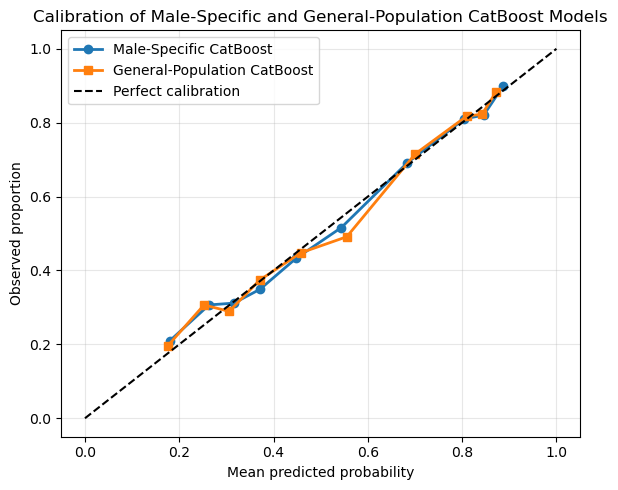

In [81]:
# H2 - BLOCK 10: Calibration plot

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Calibration curves
prob_true_male, prob_pred_male = calibration_curve(
    y_male_test,
    y_proba_male,
    n_bins=10,
    strategy='quantile'
)

prob_true_general, prob_pred_general = calibration_curve(
    y_male_test,
    y_proba_general,
    n_bins=10,
    strategy='quantile'
)


# Plot
plt.figure(figsize=(6, 5))

plt.plot(
    prob_pred_male,
    prob_true_male,
    marker='o',
    linewidth=2,
    label='Male-Specific CatBoost'
)

plt.plot(
    prob_pred_general,
    prob_true_general,
    marker='s',
    linewidth=2,
    label='General-Population CatBoost'
)

# Perfect calibration
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Perfect calibration'
)

plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion')
plt.title(
    'Calibration of Male-Specific and General-Population CatBoost Models'
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'H2_calibration_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [82]:
# H2 - BLOCK 11: Final calibration summary

brier_male = brier_score_loss(
    y_male_test,
    y_proba_male
)

brier_general = brier_score_loss(
    y_male_test,
    y_proba_general
)

observed_rate = y_male_test.mean()

mean_predicted_male = y_proba_male.mean()
mean_predicted_general = y_proba_general.mean()


h2_final_results = pd.DataFrame([
    {
        'Model': 'Male-Specific CatBoost',
        'Calibration Intercept': ci_male['Calibration Intercept'],
        'Intercept 95% CI': (
            f"({ci_male['Intercept 95% CI Lower']:.4f}, "
            f"{ci_male['Intercept 95% CI Upper']:.4f})"
        ),
        'Calibration Slope': ci_male['Calibration Slope'],
        'Slope 95% CI': (
            f"({ci_male['Slope 95% CI Lower']:.4f}, "
            f"{ci_male['Slope 95% CI Upper']:.4f})"
        ),
        'Brier Score': brier_male,
        'Mean Predicted Risk': mean_predicted_male,
        'Observed Event Rate': observed_rate
    },
    {
        'Model': 'General-Population CatBoost',
        'Calibration Intercept': ci_general['Calibration Intercept'],
        'Intercept 95% CI': (
            f"({ci_general['Intercept 95% CI Lower']:.4f}, "
            f"{ci_general['Intercept 95% CI Upper']:.4f})"
        ),
        'Calibration Slope': ci_general['Calibration Slope'],
        'Slope 95% CI': (
            f"({ci_general['Slope 95% CI Lower']:.4f}, "
            f"{ci_general['Slope 95% CI Upper']:.4f})"
        ),
        'Brier Score': brier_general,
        'Mean Predicted Risk': mean_predicted_general,
        'Observed Event Rate': observed_rate
    }
])

print("FINAL H2 CALIBRATION RESULTS")

print(
    h2_final_results.round(4).to_string(index=False)
)

h2_final_results.to_csv(
    'H2_final_calibration_results.csv',
    index=False
)

FINAL H2 CALIBRATION RESULTS
                      Model  Calibration Intercept  Intercept 95% CI  Calibration Slope     Slope 95% CI  Brier Score  Mean Predicted Risk  Observed Event Rate
     Male-Specific CatBoost                 0.0037 (-0.0672, 0.0746)             0.9703 (0.9021, 1.0386)       0.1908               0.5341               0.5345
General-Population CatBoost                 0.0038 (-0.0673, 0.0749)             0.9659 (0.8987, 1.0331)       0.1908               0.5342               0.5345


In [83]:
# H2 - BLOCK 12: Paired comparison of Brier prediction errors

from scipy.stats import ttest_rel

# Individual squared prediction errors
squared_error_male = (
    y_male_test.to_numpy() - y_proba_male
) ** 2

squared_error_general = (
    y_male_test.to_numpy() - y_proba_general
) ** 2


# Difference in squared error for each patient
brier_difference = (
    squared_error_male -
    squared_error_general
)


# Mean difference
mean_brier_difference = np.mean(
    brier_difference
)


# Paired t-test
t_stat, p_value = ttest_rel(
    squared_error_male,
    squared_error_general
)


print("H2 BRIER SCORE COMPARISON")

print(
    f"Male-specific Brier Score:       "
    f"{np.mean(squared_error_male):.4f}"
)

print(
    f"General-population Brier Score:  "
    f"{np.mean(squared_error_general):.4f}"
)

print(
    f"Mean paired difference:           "
    f"{mean_brier_difference:.4f}"
)

print(
    f"Paired t-test statistic:          "
    f"{t_stat:.4f}"
)

print(
    f"P-value:                          "
    f"{p_value:.4f}"
)

H2 BRIER SCORE COMPARISON
Male-specific Brier Score:       0.1908
General-population Brier Score:  0.1908
Mean paired difference:           0.0000
Paired t-test statistic:          0.0142
P-value:                          0.9887


In [84]:
# H2: Matching general-population training set size to male training set
n_match = len(X_male_train)

X_general_matched, _, y_general_matched, _ = train_test_split(
    X_general_train,
    y_general_train,
    train_size=n_match,
    stratify=y_general_train,
    random_state=42
)

print("Matched general-population training set:", X_general_matched.shape)
print("Cardio rate (matched general):", y_general_matched.mean())
print("Cardio rate (male train):", y_male_train.mean())

Matched general-population training set: (16051, 9)
Cardio rate (matched general): 0.5291882125724254
Cardio rate (male train): 0.5345461341972463


In [85]:
# H2: Scale and tune the matched general-population CatBoost

scaler_general_matched = StandardScaler()

X_general_matched_scaled = scaler_general_matched.fit_transform(
    X_general_matched
)

X_male_test_matched_scaled = scaler_general_matched.transform(
    X_male_test
)

grid_cat_general_matched = GridSearchCV(
    estimator=CatBoostClassifier(random_state=42, verbose=0),
    param_grid=param_grid_cat_h2,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_cat_general_matched.fit(
    X_general_matched_scaled,
    y_general_matched
)

best_cat_general_matched = grid_cat_general_matched.best_estimator_

print("MATCHED GENERAL-POPULATION CATBOOST")
print("Best parameters:", grid_cat_general_matched.best_params_)
print("Best CV AUC-ROC:", round(grid_cat_general_matched.best_score_, 4))

y_proba_general_matched = best_cat_general_matched.predict_proba(
    X_male_test_matched_scaled
)[:, 1]

MATCHED GENERAL-POPULATION CATBOOST
Best parameters: {'depth': 6, 'iterations': 500, 'learning_rate': 0.01}
Best CV AUC-ROC: 0.7813


In [88]:
# # H2: Calibration of the matched general-population model

# cal_general_matched = calculate_calibration(
#     y_male_test,
#     y_proba_general_matched
# )

# ci_general_matched = calibration_with_ci(
#     y_male_test,
#     y_proba_general_matched
# )

# brier_general_matched = brier_score_loss(
#     y_male_test,
#     y_proba_general_matched
# )

# print("MATCHED GENERAL-POPULATION CALIBRATION")
# print(cal_general_matched)
# print(ci_general_matched)
# print("Brier Score:", round(brier_general_matched, 4))

# H2: Calibration of the matched general-population model

cal_general_matched = calculate_calibration(
    y_male_test,
    y_proba_general_matched
)

ci_general_matched = calibration_with_ci(
    y_male_test,
    y_proba_general_matched
)

brier_general_matched = brier_score_loss(
    y_male_test,
    y_proba_general_matched
)

matched_summary = pd.DataFrame([{
    'Model': 'General-Population, Matched (n=16,051)',
    'Calibration Intercept': round(ci_general_matched['Calibration Intercept'], 4),
    'Intercept 95% CI': f"({ci_general_matched['Intercept 95% CI Lower']:.4f}, {ci_general_matched['Intercept 95% CI Upper']:.4f})",
    'Calibration Slope': round(ci_general_matched['Calibration Slope'], 4),
    'Slope 95% CI': f"({ci_general_matched['Slope 95% CI Lower']:.4f}, {ci_general_matched['Slope 95% CI Upper']:.4f})",
    'Brier Score': round(brier_general_matched, 4)
}])

print("MATCHED GENERAL-POPULATION CALIBRATION")
print(matched_summary.to_string(index=False))

MATCHED GENERAL-POPULATION CALIBRATION
                                 Model  Calibration Intercept  Intercept 95% CI  Calibration Slope     Slope 95% CI  Brier Score
General-Population, Matched (n=16,051)                 0.0026 (-0.0685, 0.0737)              0.973 (0.9054, 1.0406)       0.1905


In [89]:
# H2 Paired comparison (male-specific vs. matched general-population)

squared_error_general_matched = (
    y_male_test.to_numpy() - y_proba_general_matched
) ** 2

t_stat_matched, p_value_matched = ttest_rel(
    squared_error_male,
    squared_error_general_matched
)

print("H2 MATCHED-SIZE BRIER COMPARISON")
print(f"Male-specific Brier Score:            {np.mean(squared_error_male):.4f}")
print(f"Matched general-population Brier Score: {np.mean(squared_error_general_matched):.4f}")
print(f"Mean paired difference:                {np.mean(squared_error_male - squared_error_general_matched):.4f}")
print(f"Paired t-test statistic:               {t_stat_matched:.4f}")
print(f"P-value:                               {p_value_matched:.4f}")

H2 MATCHED-SIZE BRIER COMPARISON
Male-specific Brier Score:            0.1908
Matched general-population Brier Score: 0.1905
Mean paired difference:                0.0003
Paired t-test statistic:               0.4294
P-value:                               0.6677


In [90]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [91]:
# Create DataFrame for scaled test data
X_test_shap = pd.DataFrame(
    X_test_scaled,
    columns=features,
    index=X_test.index
)

print(X_test_shap.head())

       age_years       bmi     ap_hi     ap_lo  cholesterol      gluc  \
16077   0.921780 -0.955107 -0.537194 -0.272060    -0.530881 -0.397085   
2225   -1.723807 -1.059421 -1.134474 -0.272060    -0.530881 -0.397085   
6275   -1.361019  0.376836 -1.134474 -1.455280    -0.530881 -0.397085   
55588   0.561041  0.684776  0.060085  0.803595    -0.530881  1.351985   
19946  -0.624169 -0.662788 -0.537194 -0.272060    -0.530881 -0.397085   

          smoke      alco    active  
16077 -0.516866 -0.340886  0.493059  
2225  -0.516866 -0.340886  0.493059  
6275  -0.516866 -0.340886 -2.028155  
55588 -0.516866 -0.340886  0.493059  
19946 -0.516866 -0.340886  0.493059  


SHAP values shape: (4013, 9)


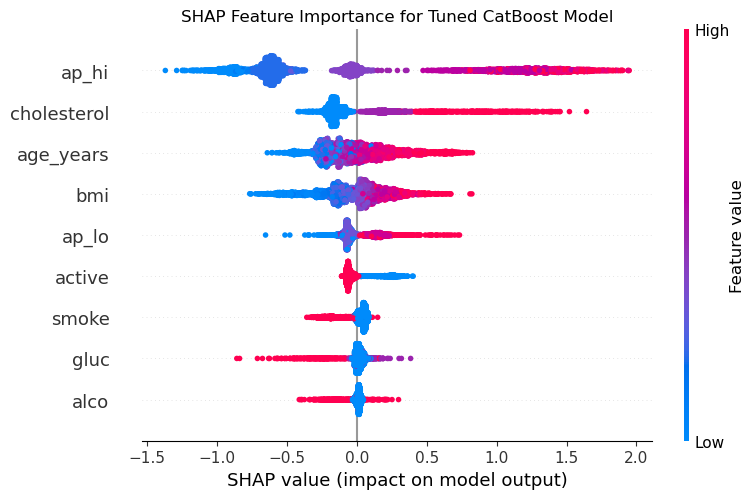

In [92]:
# SHAP analysis for tuned CatBoost

explainer = shap.TreeExplainer(best_cat_model)

shap_values = explainer.shap_values(X_test_shap)

print("SHAP values shape:", shap_values.shape)

plt.figure(figsize=(8, 5))

shap.summary_plot(
    shap_values,
    X_test_shap,
    show=False
)

plt.title(
    'SHAP Feature Importance for Tuned CatBoost Model'
)

plt.tight_layout()

plt.savefig(
    'SHAP_summary_CatBoost.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [93]:
# Mean absolute SHAP importance

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    'Feature': features,
    'Mean Absolute SHAP': mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    by='Mean Absolute SHAP',
    ascending=False
).reset_index(drop=True)

print(
    shap_importance.round(4).to_string(index=False)
)

    Feature  Mean Absolute SHAP
      ap_hi              0.7544
cholesterol              0.2413
  age_years              0.1909
        bmi              0.1711
      ap_lo              0.0996
     active              0.0838
      smoke              0.0645
       gluc              0.0417
       alco              0.0290


In [94]:
shap_importance.to_csv(
    'CatBoost_SHAP_feature_importance.csv',
    index=False
)

In [95]:
behavioural_features = [
    'smoke',
    'alco',
    'active'
]

In [96]:
behavior_shap = shap_importance[
    shap_importance['Feature'].isin(behavioural_features)
].copy()

print(
    behavior_shap.round(4).to_string(index=False)
)

Feature  Mean Absolute SHAP
 active              0.0838
  smoke              0.0645
   alco              0.0290


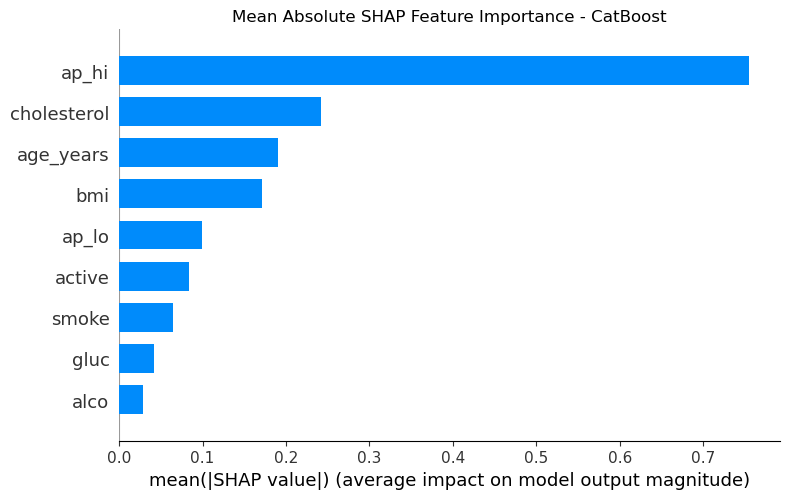

In [97]:
plt.figure(figsize=(8, 5))

shap.summary_plot(
    shap_values,
    X_test_shap,
    plot_type='bar',
    show=False
)

plt.title(
    'Mean Absolute SHAP Feature Importance - CatBoost'
)

plt.tight_layout()

plt.savefig(
    'SHAP_feature_importance_bar_CatBoost.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

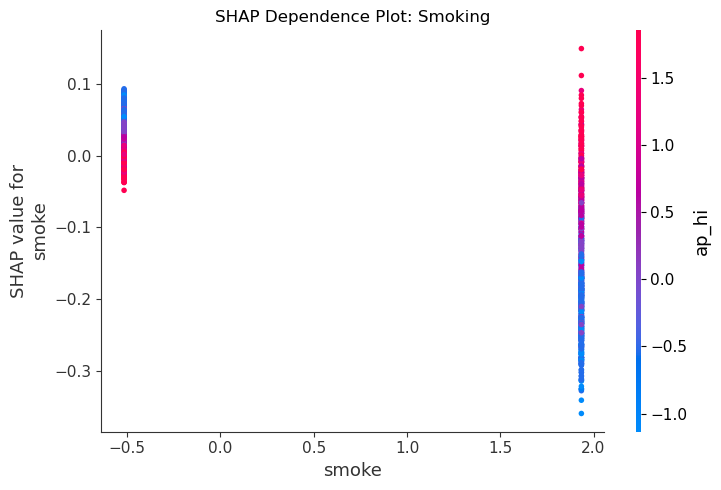

In [98]:
#Smoking
shap.dependence_plot(
    'smoke',
    shap_values,
    X_test_shap,
    show=False
)

plt.title('SHAP Dependence Plot: Smoking')
plt.tight_layout()

plt.savefig(
    'SHAP_smoke.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

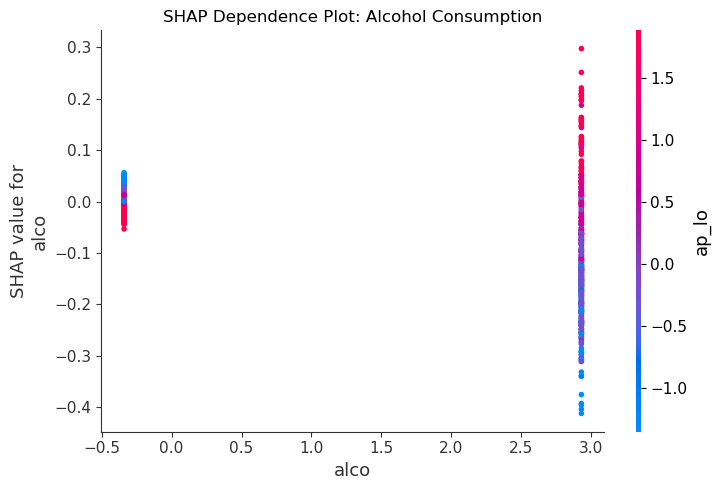

In [99]:
#Alcohol
shap.dependence_plot(
    'alco',
    shap_values,
    X_test_shap,
    show=False
)

plt.title('SHAP Dependence Plot: Alcohol Consumption')
plt.tight_layout()

plt.savefig(
    'SHAP_alcohol.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

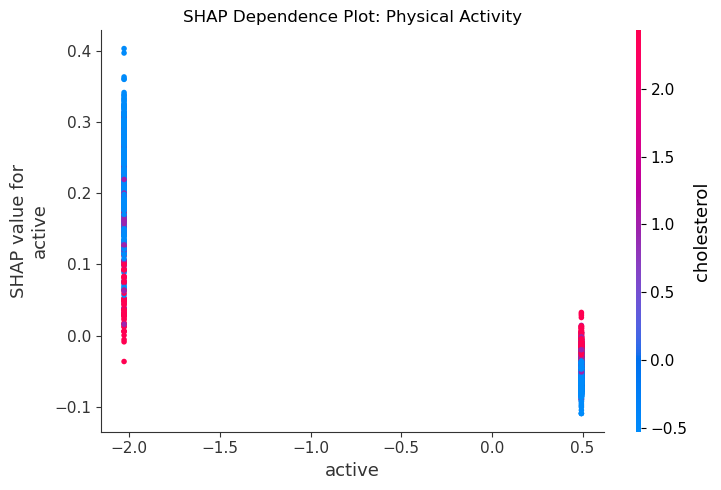

In [100]:
#Physical activity
shap.dependence_plot(
    'active',
    shap_values,
    X_test_shap,
    show=False
)

plt.title('SHAP Dependence Plot: Physical Activity')
plt.tight_layout()

plt.savefig(
    'SHAP_physical_activity.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [101]:
_check_male = df[(df['gender']==2) & (df['age_years']>=45) &
                  (df['ap_hi']>=60) & (df['ap_hi']<=250) &
                  (df['ap_lo']>=30) & (df['ap_lo']<=180) &
                  (df['ap_hi']>df['ap_lo']) &
                  (df['height']>=140) & (df['height']<=210) &
                  (df['weight']>=35) & (df['weight']<=200)].copy()
_check_male['bmi'] = _check_male['weight'] / (_check_male['height']/100)**2

print(_check_male.groupby('cardio')[['age_years','bmi','ap_hi','ap_lo']].agg(['mean','std']).round(2))
print(_check_male.groupby('cardio')[['cholesterol','gluc','smoke','alco','active']].mean().round(3))

       age_years          bmi         ap_hi         ap_lo      
            mean   std   mean   std    mean    std   mean   std
cardio                                                         
0          54.36  5.23  25.94  4.07  121.92  12.30  79.50  7.80
1          55.93  5.35  27.48  4.45  135.22  17.67  85.24  9.74
        cholesterol   gluc  smoke   alco  active
cardio                                          
0             1.216  1.188  0.228  0.111   0.828
1             1.480  1.258  0.200  0.098   0.786


In [102]:
_check_bp_band = pd.cut(df_clean.ap_hi, [0, 119, 129, 139, 159, 300],
                         labels=['<120', '120-129', '130-139', '140-159', '>=160'])
print(df_clean.groupby(_check_bp_band).cardio.agg(['mean', 'count']).round(3))

          mean  count
ap_hi                
<120     0.294   2576
120-129  0.371   8356
130-139  0.574   2959
140-159  0.827   4571
>=160    0.865   1602


C:\Users\Acer\AppData\Local\Temp\ipykernel_21412\789988727.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df_clean.groupby(_check_bp_band).cardio.agg(['mean', 'count']).round(3))


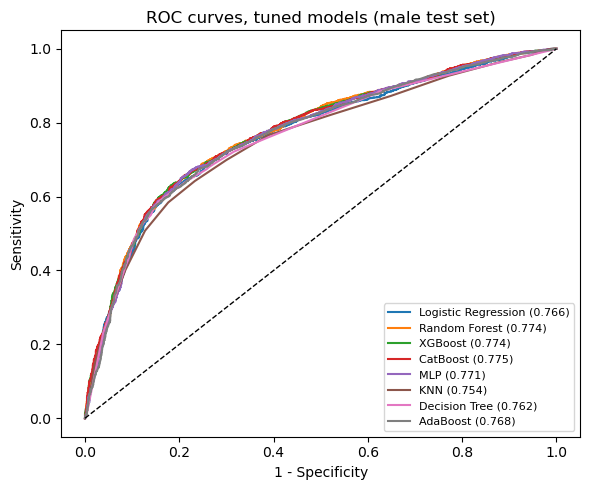

Found and plotted: ['best_lr_model', 'best_rf_model', 'best_xgb_model', 'best_cat_model', 'best_mlp_model', 'best_knn_model', 'best_dt_model', 'best_ada_model']


In [103]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Expected variable names, following the pattern you're using
model_vars = {
    'Logistic Regression': 'best_lr_model',
    'Random Forest': 'best_rf_model',
    'XGBoost': 'best_xgb_model',
    'CatBoost': 'best_cat_model',
    'MLP': 'best_mlp_model',
    'KNN': 'best_knn_model',
    'Decision Tree': 'best_dt_model',
    'AdaBoost': 'best_ada_model',
}

plt.figure(figsize=(6,5))
found = []
missing = []

for name, varname in model_vars.items():
    if varname in globals():
        model = globals()[varname]
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc_val = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, label=f'{name} ({auc_val:.3f})')
        found.append(varname)
    else:
        missing.append(varname)

plt.plot([0,1],[0,1],'k--', linewidth=1)
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title('ROC curves, tuned models (male test set)')
plt.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig('roc_tuned_verified.png', dpi=300)
plt.show()

print("Found and plotted:", found)
if missing:
    print("NOT FOUND (missing from plot):", missing)

C:\Users\Acer\AppData\Local\Temp\ipykernel_21412\3628831763.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='cardio', data=df_clean, palette=['#9FB6CF', '#2F5572'])
C:\Users\Acer\AppData\Local\Temp\ipykernel_21412\3628831763.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Absent', 'Present'])


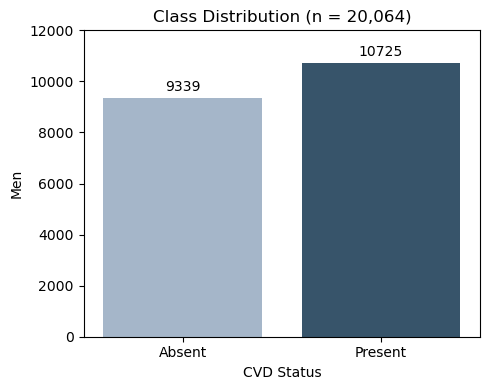

In [104]:
plt.figure(figsize=(5,4))

ax = sns.countplot(x='cardio', data=df_clean, palette=['#9FB6CF', '#2F5572'])

ax.set_xticklabels(['Absent', 'Present'])

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.title('Class Distribution (n = 20,064)')
plt.xlabel('CVD Status')
plt.ylabel('Men')

plt.ylim(0, 12000)

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=200, bbox_inches='tight')
plt.show()

In [105]:
df.dtypes

id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
age_years      float64
dtype: object

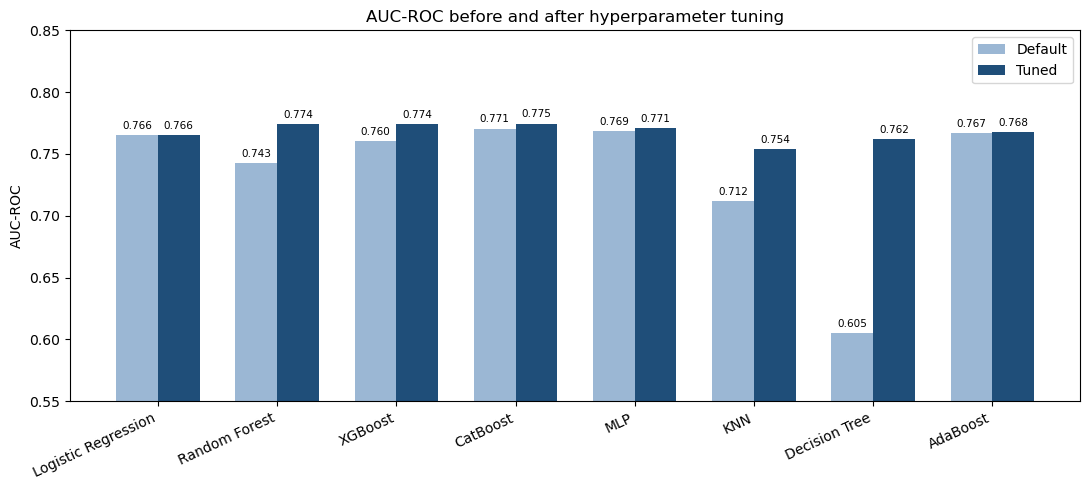

In [106]:
import matplotlib.pyplot as plt
import numpy as np

default_df = results_df.copy()
tuned_df = tuned_results_df.copy()

default_df['Model_clean'] = default_df['Model'].str.replace(' (Tuned)', '', regex=False)
tuned_df['Model_clean'] = tuned_df['Model'].str.replace(' (Tuned)', '', regex=False)

models = ['Logistic Regression', 'Random Forest', 'XGBoost', 'CatBoost',
          'MLP', 'KNN', 'Decision Tree', 'AdaBoost']

default_auc = [default_df.loc[default_df['Model_clean'] == m, 'AUC-ROC'].values[0] for m in models]
tuned_auc   = [tuned_df.loc[tuned_df['Model_clean'] == m, 'AUC-ROC'].values[0] for m in models]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
bars1 = ax.bar(x - width/2, default_auc, width, label='Default', color='#9bb7d4')
bars2 = ax.bar(x + width/2, tuned_auc, width, label='Tuned', color='#1f4e79')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=7.5)

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=25, ha='right')
ax.set_ylabel('AUC-ROC')
ax.set_ylim(0.55, 0.85)
ax.set_title('AUC-ROC before and after hyperparameter tuning')
ax.legend()
plt.tight_layout()
plt.savefig('auc_default_vs_tuned_verified.png', dpi=300)
plt.show()

In [107]:
print(X_test.columns.tolist())
print(X_test.index[:5], X_test_scaled[:2])

['age_years', 'bmi', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']
Index([16077, 2225, 6275, 55588, 19946], dtype='int64') [[ 0.92178002 -0.9551065  -0.53719435 -0.27206003 -0.53088133 -0.39708506
  -0.51686639 -0.3408857   0.49305901]
 [-1.72380687 -1.05942124 -1.13447389 -0.27206003 -0.53088133 -0.39708506
  -0.51686639 -0.3408857   0.49305901]]


In [108]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, brier_score_loss

# Predicted probabilities for the whole test set, computed once
y_proba_all = best_cat_model.predict_proba(X_test_scaled)[:, 1]
y_test_arr = np.asarray(y_test)

# Define subgroups using the ORIGINAL (unscaled) test values
subgroups = {
    'Age 45-54':          X_test['age_years'] < 55,
    'Age 55-64':           X_test['age_years'] >= 55,
    'Non-smoker':          X_test['smoke'] == 0,
    'Smoker':              X_test['smoke'] == 1,
    'Physically active':   X_test['active'] == 1,
    'Physically inactive': X_test['active'] == 0,
    'BMI below 25':        X_test['bmi'] < 25,
    'BMI 25-29.9':         (X_test['bmi'] >= 25) & (X_test['bmi'] < 30),
    'BMI 30 or above':     X_test['bmi'] >= 30,
    'Cholesterol normal':  X_test['cholesterol'] == 1,
    'Cholesterol elevated':X_test['cholesterol'] > 1,
}

n_bootstrap = 1000
rng = np.random.default_rng(42)
results = []

for name, mask in subgroups.items():
    mask = np.asarray(mask)
    y_sub = y_test_arr[mask]
    p_sub = y_proba_all[mask]

    n = mask.sum()
    prevalence = y_sub.mean()
    auc = roc_auc_score(y_sub, p_sub)
    brier = brier_score_loss(y_sub, p_sub)

    # Bootstrap 95% CI for AUC within this subgroup
    boot_aucs = []
    for _ in range(n_bootstrap):
        idx = rng.choice(n, size=n, replace=True)
        if len(np.unique(y_sub[idx])) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_sub[idx], p_sub[idx]))
    ci_lower, ci_upper = np.percentile(boot_aucs, [2.5, 97.5])

    results.append({
        'Subgroup': name,
        'n': n,
        'CVD prevalence': f"{prevalence:.1%}",
        'AUC-ROC': round(auc, 3),
        '95% CI': f"({ci_lower:.3f}-{ci_upper:.3f})",
        'Brier': round(brier, 3)
    })

subgroup_df = pd.DataFrame(results)
print(subgroup_df.to_string(index=False))

            Subgroup    n CVD prevalence  AUC-ROC        95% CI  Brier
           Age 45-54 1958          48.4%    0.790 (0.771-0.809)  0.180
           Age 55-64 2055          58.2%    0.743 (0.721-0.765)  0.201
          Non-smoker 3116          54.1%    0.770 (0.753-0.787)  0.193
              Smoker  897          51.3%    0.791 (0.763-0.820)  0.185
   Physically active 3247          52.2%    0.775 (0.758-0.790)  0.191
 Physically inactive  766          58.9%    0.767 (0.734-0.800)  0.192
        BMI below 25 1578          45.4%    0.768 (0.743-0.791)  0.189
         BMI 25-29.9 1632          54.6%    0.766 (0.742-0.787)  0.193
     BMI 30 or above  803          67.0%    0.724 (0.687-0.761)  0.190
  Cholesterol normal 3067          47.9%    0.751 (0.733-0.768)  0.198
Cholesterol elevated  946          71.5%    0.758 (0.723-0.790)  0.166
